# 11 — Pixels and Language

“Look at the green ball”: a head camera, a colour, a turn, and a check ·
SOC4180 Robot and AI

Hong Jeong

<figure>
<a
href="https://colab.research.google.com/github/gnoejh/soc4180/blob/main/weeks/11-pixels-and-language/lab.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

**Before you start, two things:**

1.  **Runtime → Change runtime type → T4 GPU.** This week renders camera
    pictures, and on Colab rendering needs the GPU runtime (EGL).
    Nothing here trains on the GPU; on your laptop any OpenGL renders.
2.  **File → Save a copy in Drive.** This notebook is opened from GitHub
    and is *not* saved. Without a copy, your work disappears when you
    close the tab.

The setup cell downloads this week’s `lab.py`; every code slide is that
file.

## “Look at the green ball”

The G1 stands in front of four coloured balls with a camera in its head.
It is told, in words, which one to look at. This week’s one file,
`lab.py`, does it in four steps:

1.  **Words → a colour.** Pick the colour out of the sentence; refuse a
    word it does not know.
2.  **Pixels → a direction.** Find that colour in the camera picture
    (`find_ball`, the function you change).
3.  **A turn.** Turn the waist until the ball sits in the middle of the
    picture (a P controller, week 5).
4.  **A check.** Look again and confirm, *with the picture*; refuse if
    the ball is not there.

Steps 1 and 2 have famous learned versions (a convolutional network, a
vision-language model); we meet them on two slides with their measured
numbers. **The week’s point is step 4**: a robot that acts on what it
believes must check, and a check made with the same sense that was wrong
passes its own mistake.

**Layer:** the camera is a Layer 2 sensor; reading it, and the words,
are Layer 5.

------------------------------------------------------------------------

## Where this week sits on the map

Week 8 opened with a map of RL methods (value- or policy-based,
model-based or free, on- or off-policy, table or function). The course’s
route through it:

| week | method | what is learned | the step from the week before |
|---------|--------------------|------------------|--------------------------|
| 7 | value iteration | $V^*$, $\pi^*$ on a grid | exact, but needs $P$ and $R$ as tables |
| 7b | Q-learning, SARSA | a $Q$ table | drops $P$: learns from samples |
| 8 | policy gradient, parameter-space search | one ankle gain $\theta$ | drops the table: a policy with a parameter |
| 9 | PPO + domain randomisation | two networks (shipped) | scales $\theta$ to a network; trains in many worlds |
| 10 | MPPI; behaviour cloning | a plan every step; a copy | uses the simulator as a model; learns from an expert, not a reward |
| **11 (this week)** | **perception and a check** | **—** | **the policy’s input becomes pixels and words** |

The policy’s **input** changes: from a tilt to **pixels** and **words**.
Their learned versions (a CNN, a vision–language model) are trained like
week 9’s networks; this week’s point is the **check** that any learned
policy needs.

------------------------------------------------------------------------

## Setting up

In [1]:
import importlib.util, sys, urllib.request
from pathlib import Path
try:
    on_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:          # no `google` package at all: certainly not Colab
    on_colab = False
if on_colab:
    %pip install -q --upgrade "soc4180[rl] @ git+https://github.com/gnoejh/soc4180.git"
    urllib.request.urlretrieve("https://raw.githubusercontent.com/gnoejh/soc4180/main/weeks/11-pixels-and-language/lab.py", "lab.py")
sys.path.insert(0, str(Path.cwd()))
import soc4180, lab          # soc4180 first: it selects the GL backend before mujoco loads

import inspect, math, time
import numpy as np
import matplotlib.pyplot as plt
import mujoco, torch
from soc4180.agent import Body                     # the G1 + four mocap balls + a head camera
from soc4180.render import _new_renderer
from soc4180.vision import COLOURS, CAMERA, ball_direction
torch.set_num_threads(4)                           # torch is imported by soc4180.vision; fixed, as every script
t_start = time.time()
body = Body()
lab.scene(body, 1)                                 # scene 1 of the lab's battery
print(f"cameras {body.model.ncam}, balls {body.model.nmocap}: {', '.join(COLOURS)}; "
      f"camera '{CAMERA}', {lab.RESOLUTION} x {lab.RESOLUTION} pixels")

cameras 1, balls 4: red, green, blue, yellow; camera 'head', 64 x 64 pixels

`Body` is the G1 standing on its servos, plus a camera on `torso_link`
and four balls that are **mocap** bodies: no joint, no physics, moved by
writing `data.mocap_pos`. `lab.scene(body, seed)` puts the balls at
seeded random directions, as the lab’s test battery does.

------------------------------------------------------------------------

## Colour code for the week

| symbol | meaning | colour |
|------------------------|------------------------|------------------------|
| ${\color{#3b7dd8}{a,\ e}}$; ${\color{#3b7dd8}{X,\ Y,\ Z}}$ | a **direction** (azimuth, left +; elevation, up +); a point in the camera’s frame (right, up, forward) | <span style="color:#3b7dd8">blue</span> |
| ${\color{#e8743b}{u,\ v,\ f}}$ | **picture** coordinates (across, down, $-1..+1$) and the focal length | <span style="color:#e8743b">orange</span> |
| ${\color{#2a9d5c}{\mathbf{c},\ \mathbf{p}}}$ | **colours** in RGB, $0..1$: the ball’s, and one pixel’s | <span style="color:#2a9d5c">green</span> |
| ${\color{#c0392b}{d,\ \tau}}$ | a **colour distance**, and the threshold it is compared with (`THRESHOLD`) | <span style="color:#c0392b">red</span> |
| ${\color{#8e44ad}{g}}$ | the **gain** of the turning loop (`GAIN`) | <span style="color:#8e44ad">purple</span> |

Four questions, in order: *how does a point land on a pixel*, *how do
you find a colour in a picture*, *what happens when the robot turns on
it*, and *how does it know it worked*.

------------------------------------------------------------------------

## The camera: a body-fixed frame

``` python
spec = mujoco.MjSpec.from_file(str(soc4180.robot_path()))       # inside soc4180.vision.camera_model
spec.body("torso_link").add_camera(name="head", pos=[0.08, 0, 0.45],
                                   xyaxes=[0, -1, 0, 0, 0, 1], fovy=90)
ball = spec.worldbody.add_body(name="ball_green", mocap=True, pos=[1.2, 0, 0.8])
ball.add_geom(type=mujoco.mjtGeom.mjGEOM_SPHERE, size=[0.15, 0, 0],
              rgba=[0.1, 0.8, 0.1, 1], contype=0, conaffinity=0)
```

- A camera hangs on a **body**, like a site: it moves with the torso.
  The G1 has no neck, so **the waist is the only way to aim it**.
- MuJoCo cameras look down their own **−z**. `xyaxes` names the camera’s
  x (picture right) and y (picture up) in the body frame: right = torso
  −y, up = +z, so it looks along +x, forward.
- `fovy = 90`: the picture spans 90° top to bottom, so its edge is 45°
  from the middle. The picture is square, so the same holds across.
- `contype = conaffinity = 0`: nothing can touch a ball. It is a target,
  not an object.

------------------------------------------------------------------------

## `Body`: the robot `lab.py` drives

In [2]:
waist = body.act("waist_yaw")
print(f"body.act('waist_yaw') = {waist}   body.act_q[{waist}] = {body.act_q[waist]}   "
      f"ctrl range {np.round(body.model.actuator_ctrlrange[waist], 3)} rad   timestep {body.model.opt.timestep} s")
print(f"standing {body.standing}   pelvis height {body.data.qpos[2]:.3f} m   frames {len(body.frames)}")
body.step(0.1)
print(f"after body.step(0.1): time {body.data.time:.3f} s, frames {len(body.frames)}\n")
lab.scene(body, 1)                                 # back to scene 1, exactly as it was
print(inspect.getsource(Body.step))

body.act('waist_yaw') = 12   body.act_q[12] = 19   ctrl range [-2.618  2.618] rad   timestep 0.002 s
standing True   pelvis height 0.790 m   frames 0
after body.step(0.1): time 0.100 s, frames 2

    def step(self, seconds: float):
        """Run the physics with the current ``ctrl``, keeping the balls where they are."""
        d = self.data
        for _ in range(int(round(seconds / self.model.opt.timestep))):
            d.mocap_pos[:] = self.balls
            mujoco.mj_step(self.model, d)
            if round(d.time / self.model.opt.timestep) % 17 == 0:
                self.frames.append(d.qpos.copy())


`Body` lives in `soc4180.agent`. `lab.py` never calls `mujoco.mj_step`
itself: it sets a servo target in `body.data.ctrl` and asks the body to
run.

------------------------------------------------------------------------

## `Body`, piece by piece

| code | what it does | why `lab.py` needs it |
|------------------------|------------------------|------------------------|
| `Body()` | builds `camera_model(NAMES, radius=0.15)` (the G1, the `head` camera, four mocap balls of radius 0.15 m) and its `MjData` | one robot for every test; `body.model`, `body.data` are MuJoCo’s two objects |
| `body.act("waist_yaw")` | a joint name → its **actuator** index | `body.data.ctrl[w]` is that servo’s target angle |
| `body.act_q[w]` | an actuator index → the `qpos` slot of its joint | to read the angle the waist *reached*, not the one commanded |
| `body.step(0.1)` | `mj_step` until 0.1 s has passed, with the current `ctrl` | the servos move; the turn happens here |

*(continued on the next slide)*

------------------------------------------------------------------------

## `Body`, piece by piece (cont.)

| code | what it does | why `lab.py` needs it |
|------------------------|------------------------|------------------------|
| `d.mocap_pos[:] = self.balls` (inside `step`) | puts every ball back at its stored **world** position each step | the balls stay still while the camera turns |
| `body.standing` | pelvis height `qpos[2] > 0.6` m and pelvis tilt under 20° | a property, no `()`; `obey` fails a look that fell |
| `body.reset(balls)` | the `stand` keyframe, the balls placed from the camera, `ctrl` = the standing targets | every test starts from the same standing robot |
| `body.frames` | a copy of `qpos` every 17 physics steps; `reset` empties it | the replay at the end of `main` |

------------------------------------------------------------------------

## `scene`, from `lab.py`

In [3]:
print(inspect.getsource(lab.scene))
for seed in (1, 2):
    lab.scene(body, seed)
    print(f"scene {seed}: " + "   ".join(f"{n} {math.degrees(ball_direction(body.model, body.data, i)[0]):+5.1f} deg"
                                     for i, n in enumerate(COLOURS)))
lab.scene(body, 1)

def scene(body, seed, hide=None):
    """Balls at random directions (seeded); `hide` puts one behind the robot."""
    rng = np.random.default_rng(seed)
    az = rng.permutation(np.linspace(-0.7, 0.7, 4)) + rng.uniform(-0.1, 0.1, 4)
    balls = {n: (float(a), float(rng.uniform(-0.2, 0.15)), float(rng.uniform(1.4, 2.2)))
             for n, a in zip(("red", "green", "blue", "yellow"), az)}
    if hide:
        balls[hide] = (math.pi, 0.0, 2.0)
    body.reset(balls)

scene 1: red -44.2 deg   green  -8.2 deg   blue +11.2 deg   yellow +39.2 deg
scene 2: red +43.7 deg   green  +8.7 deg   blue -39.0 deg   yellow -10.7 deg

The printed angles are each ball’s ${\color{#3b7dd8}{a}}$ from the
camera (left +), read back from the simulator: the azimuths `scene`
asked for.

------------------------------------------------------------------------

## `scene`, line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `np.random.default_rng(seed)` | a random generator fixed by `seed` | the same seed is the same scene on every run: the battery uses seeds 1 and 2, `--say` seed 0 |
| `np.linspace(-0.7, 0.7, 4)` | four evenly spaced ${\color{#3b7dd8}{a}}$: −0.7, −0.23, +0.23, +0.7 rad (±40°) | spread across the 90° picture, never on top of each other |
| `rng.permutation(...)` | shuffles which colour gets which slot | any colour can be at the edge |
| `+ rng.uniform(-0.1, 0.1, 4)` | moves each by up to 0.1 rad | not the same four angles every time; an edge ball can reach the picture’s edge (red, scene 1: −44°) |

*(continued on the next slide)*

------------------------------------------------------------------------

## `scene`, line by line (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `rng.uniform(-0.2, 0.15)` | the elevation ${\color{#3b7dd8}{e}}$, radians, up + | a little above or below the camera |
| `rng.uniform(1.4, 2.2)` | the distance from the camera, metres | the ball’s size in the picture changes |
| `balls[hide] = (math.pi, 0.0, 2.0)` | ${\color{#3b7dd8}{a}} = \pi$: straight **behind** the robot, level, 2 m | the test where the right answer is “I do not see it” |
| `body.reset(balls)` | stands the robot and places the balls (`vision.place_ball`) | a fresh start for each test |

------------------------------------------------------------------------

## What the robot sees

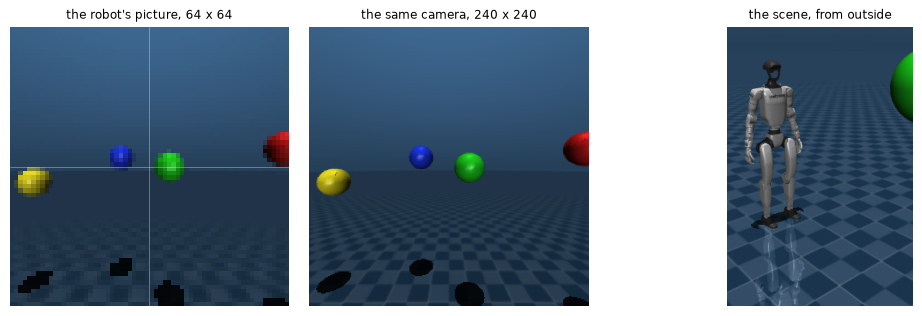

In [4]:
with _new_renderer(body.model, lab.RESOLUTION, lab.RESOLUTION) as r:
    r.update_scene(body.data, camera=CAMERA); picture = r.render().copy()      # exactly what lab.py sees
with _new_renderer(body.model, 240, 240) as r:
    r.update_scene(body.data, camera=CAMERA); big = r.render().copy()
with _new_renderer(body.model, 240, 360) as r:
    r.update_scene(body.data); outside = r.render().copy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
for ax, img, title in ((axes[0], picture, f"the robot's picture, {lab.RESOLUTION} x {lab.RESOLUTION}"),
                       (axes[1], big, "the same camera, 240 x 240"), (axes[2], outside, "the scene, from outside")):
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis("off")
axes[0].axhline(31.5, color="w", lw=0.4, alpha=0.6); axes[0].axvline(31.5, color="w", lw=0.4, alpha=0.6)
fig.tight_layout(); plt.show()

The lab works on the left picture: 64 × 64 pixels is enough to find a
ball by its colour. The white lines mark the middle, where the robot
wants the named ball to be.

------------------------------------------------------------------------

## From a direction to a pixel

**Step 1: similar triangles.** A pinhole camera with its picture at
distance ${\color{#e8743b}{f}}$ puts a point
(${\color{#3b7dd8}{X}}, {\color{#3b7dd8}{Y}}, {\color{#3b7dd8}{Z}}$)
(right, up, forward) at
${\color{#e8743b}{f}}{\color{#3b7dd8}{X}}/{\color{#3b7dd8}{Z}}$ across
and ${\color{#e8743b}{f}}{\color{#3b7dd8}{Y}}/{\color{#3b7dd8}{Z}}$ up.
A camera **divides by depth**: twice as far in the same direction is the
same pixel.

**Step 2: the direction as a point.** A ball at distance $D$, azimuth
${\color{#3b7dd8}{a}}$ (left +), elevation ${\color{#3b7dd8}{e}}$ (up
+):
$${\color{#3b7dd8}{X}} = -D\cos{\color{#3b7dd8}{e}}\sin{\color{#3b7dd8}{a}},\quad
{\color{#3b7dd8}{Y}} = D\sin{\color{#3b7dd8}{e}},\quad
{\color{#3b7dd8}{Z}} = D\cos{\color{#3b7dd8}{e}}\cos{\color{#3b7dd8}{a}}$$
(the minus: azimuth counts to the left, the picture’s x points right).

**Step 3: divide by depth**, with ${\color{#e8743b}{f}} = 1$ and
${\color{#e8743b}{v}}$ counting **down**; $D$ cancels:
$${\color{#e8743b}{u}} = \frac{{\color{#3b7dd8}{X}}}{{\color{#3b7dd8}{Z}}} = -\tan{\color{#3b7dd8}{a}}, \qquad
{\color{#e8743b}{v}} = -\frac{{\color{#3b7dd8}{Y}}}{{\color{#3b7dd8}{Z}}} = -\frac{\tan{\color{#3b7dd8}{e}}}{\cos{\color{#3b7dd8}{a}}}
\qquad\Longrightarrow\qquad {\color{#3b7dd8}{a}} = \arctan(-{\color{#e8743b}{u}})$$

The $\cos{\color{#3b7dd8}{e}}$ cancels in ${\color{#e8743b}{u}}$: **the
column depends on the azimuth alone**, whatever the height. So turning
needs only ${\color{#e8743b}{u}}$, and `lab.py` computes
`azimuth = math.atan(-u)`. With a 90° view the edge is $\tan 45° = 1$,
so ${\color{#e8743b}{u}} \in [-1, 1]$ fills the picture.

------------------------------------------------------------------------

## Checking the formula against the simulator

In [5]:
img = picture
for i, name in enumerate(COLOURS):
    u, v = lab.find_ball(img, COLOURS[name])                        # the lab's detector (next slides)
    seen = math.degrees(math.atan(-u))                              # pixel -> azimuth, as in lab.obey
    true = math.degrees(ball_direction(body.model, body.data, i)[0])  # from the simulator's ball position
    print(f"{name:6s}  u = {u:+.3f}   atan(-u) = {seen:+6.1f} deg   simulator: {true:+6.1f} deg   "
          f"difference {seen - true:+.1f}")
print(f"10 degrees is {32 * math.tan(math.radians(10)):.1f} pixels near the middle, "
      f"{32 * (1 - math.tan(math.radians(35))):.1f} between 35 and 45 degrees")

red     u = +0.969   atan(-u) =  -44.1 deg   simulator:  -44.2 deg   difference +0.1
green   u = +0.151   atan(-u) =   -8.6 deg   simulator:   -8.2 deg   difference -0.4
blue    u = -0.203   atan(-u) =  +11.5 deg   simulator:  +11.2 deg   difference +0.3
yellow  u = -0.863   atan(-u) =  +40.8 deg   simulator:  +39.2 deg   difference +1.5
10 degrees is 5.6 pixels near the middle, 9.6 between 35 and 45 degrees

`ball_direction` reads the ball’s true position out of the simulator;
the robot never sees it. The picture agrees with it to within 1.5°, from
a 64-pixel picture and one line of trigonometry. And because of the
$\tan$, pixels are **not evenly spaced in angle**: the same 10° covers
fewer pixels near the middle than near the edge.

------------------------------------------------------------------------

## A picture is numbers

In [6]:
print(f"picture: shape {img.shape}, dtype {img.dtype}, {img.size:,} numbers from {img.min()} to {img.max()}")
u, v = lab.find_ball(img, COLOURS["green"])
col, row = int((u + 1) / 2 * img.shape[1]), int((v + 1) / 2 * img.shape[0])
for label, (rr, cc) in (("at the green ball", (row, col)), ("top-left corner", (0, 0)), ("bottom row", (63, 32))):
    p = img[rr, cc] / 255.0
    d = np.linalg.norm(p - np.asarray(COLOURS["green"]))
    print(f"pixel (row {rr:2d}, col {cc:2d}) {label:18s} RGB {np.round(p, 2)}   distance to green {d:.2f}")
print("green ball's colour in the model:", COLOURS["green"])

picture: shape (64, 64, 3), dtype uint8, 12,288 numbers from 2 to 231
pixel (row 30, col 36) at the green ball  RGB [0.12 0.78 0.12]   distance to green 0.04
pixel (row  0, col  0) top-left corner    RGB [0.22 0.38 0.53]   distance to green 0.61
pixel (row 63, col 32) bottom row         RGB [0.15 0.23 0.31]   distance to green 0.61
green ball's colour in the model: (0.1, 0.8, 0.1)

Each pixel is three numbers (red, green, blue), stored as `uint8`, 0 to
255; divided by 255 they are a point ${\color{#2a9d5c}{\mathbf{p}}}$ in
the unit cube. The ball is drawn with colour
${\color{#2a9d5c}{\mathbf{c}}}$, but its pixels are not exactly
${\color{#2a9d5c}{\mathbf{c}}}$: lighting shades the sphere. So “find
green” cannot mean “find pixels equal to green”. It has to mean *close
to* green.

------------------------------------------------------------------------

## The simplest detector

**Close to the colour.** For every pixel, the straight-line distance in
RGB:
$${\color{#c0392b}{d}}_{ij} = \lVert {\color{#2a9d5c}{\mathbf{p}}}_{ij} - {\color{#2a9d5c}{\mathbf{c}}} \rVert
= \sqrt{(r_{ij} - c_r)^2 + (g_{ij} - c_g)^2 + (b_{ij} - c_b)^2}, \qquad 0 \le {\color{#c0392b}{d}} \le \sqrt 3 \approx 1.73$$
A pixel **counts** if
${\color{#c0392b}{d}}_{ij} < {\color{#c0392b}{\tau}}$ (`THRESHOLD`, 0.25
as shipped). Call the set of counted pixels $S$, with $|S|$ members.

**Not there.** If $|S| <$ `MIN_PIXELS` (4), answer *none*. This is the
detector saying “I do not see it”, and the lab’s refusal depends on it.

**Where.** The centre of the counted pixels (their mean row and column),
as picture coordinates, a pixel’s centre at $+0.5$:
$${\color{#e8743b}{u}} = \frac{\overline{\text{col}} + 0.5}{W}\cdot 2 - 1, \qquad
{\color{#e8743b}{v}} = \frac{\overline{\text{row}} + 0.5}{H}\cdot 2 - 1$$

No learning and no model of a ball: a colour, a distance, a count, a
mean. Every number it uses is one you can print, which is why it is the
one you change.

------------------------------------------------------------------------

## `find_ball`, from `lab.py`

In [7]:
print(f"THRESHOLD = {lab.THRESHOLD}      MIN_PIXELS = {lab.MIN_PIXELS}\n")
print(inspect.getsource(lab.find_ball))

THRESHOLD = 0.25      MIN_PIXELS = 4

def find_ball(image, rgb):
    pixels = image.astype(float) / 255.0
    distance = np.linalg.norm(pixels - np.asarray(rgb), axis=-1)       # (H, W)
    rows, cols = np.nonzero(distance < THRESHOLD)
    if len(rows) < MIN_PIXELS:
        return None
    h, w = distance.shape
    u = (cols.mean() + 0.5) / w * 2 - 1
    v = (rows.mean() + 0.5) / h * 2 - 1
    return u, v


Each line is one line of the last slide: scale to $0..1$, the distance
image `(H, W)`, `np.nonzero` for the set $S$, the count test, the two
means. `image` is the `(64, 64, 3)` picture; `rgb` is the colour from
step 1. It returns `(u, v)` or `None`.

------------------------------------------------------------------------

## `find_ball`, line by line: the distance

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `image.astype(float) / 255.0` | `uint8` 0..255 → floats 0..1, still `(64, 64, 3)` | the same scale as `rgb`: `COLOURS` are 0..1 |
| `np.asarray(rgb)` | the ball’s colour ${\color{#2a9d5c}{\mathbf{c}}}$ as an array of 3 | a tuple cannot be subtracted from an array |
| `pixels - np.asarray(rgb)` | NumPy **broadcasts** `(64, 64, 3)` minus `(3,)`: ${\color{#2a9d5c}{\mathbf{p}}}_{ij} - {\color{#2a9d5c}{\mathbf{c}}}$ for every pixel | 4,096 subtractions, no loop |
| `np.linalg.norm(..., axis=-1)` | the length along the last axis (r, g, b), so `distance` is `(H, W)` | ${\color{#c0392b}{d}}_{ij}$, one number per pixel |
| `# (0..1.7)` (the comment on `THRESHOLD`) | 0 is the exact colour; the most is opposite corners of the colour cube, black to white, $\sqrt 3 \approx 1.73$ | the scale ${\color{#c0392b}{\tau}}$ = 0.25 is read on |

In [8]:
print("black to white:", np.linalg.norm(np.array([1.0, 1.0, 1.0]) - np.array([0.0, 0.0, 0.0])))

black to white: 1.7320508075688772

------------------------------------------------------------------------

## `find_ball`, line by line: where

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `distance < THRESHOLD` | `True` where ${\color{#c0392b}{d}} < {\color{#c0392b}{\tau}}$: a `(64, 64)` mask | the set $S$ |
| `rows, cols = np.nonzero(...)` | the row and the column of every `True`, two arrays of length $\lvert S\rvert$ | the positions of the counted pixels |
| `if len(rows) < MIN_PIXELS: return None` | fewer than 4 counted pixels → `None` | “not there”: `obey` turns it into a refusal |
| `cols.mean()`, `rows.mean()` | the centroid: the mean column and row (may be a fraction) | the blob’s centre is the ball’s direction |

*(continued on the next slide)*

------------------------------------------------------------------------

## `find_ball`, line by line: where (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `+ 0.5` | pixel `c` covers `c` to `c + 1`; its centre is `c + 0.5` | without it every answer is half a pixel off, and the middle would not be 0 |
| `/ w * 2 - 1` (`h, w = distance.shape`) | `0 .. w` → ${\color{#e8743b}{u}}$ in `-1 .. +1`; the same for ${\color{#e8743b}{v}}$ with `h` | the ${\color{#e8743b}{u}}$ of *From a direction to a pixel*: $\tan 45° = 1$ at the edge |
| `return u, v` | `obey` uses only `u` | the column alone gives the azimuth |

In [9]:
print("   ".join(f"column {c}: u = {(c + 0.5) / 64 * 2 - 1:+.3f}" for c in (0, 31.5, 63)))

column 0: u = -0.984   column 31.5: u = +0.000   column 63: u = +0.984

------------------------------------------------------------------------

## What `find_ball` sees

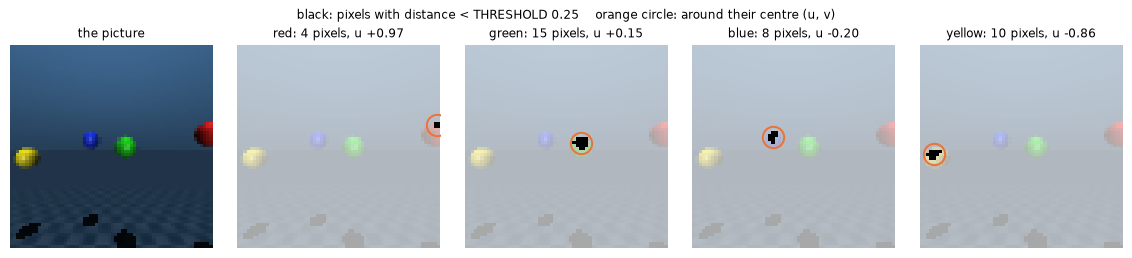

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(12, 2.7))
axes[0].imshow(img); axes[0].set_title("the picture", fontsize=9); axes[0].axis("off")
for ax, name in zip(axes[1:], COLOURS):
    d = np.linalg.norm(img / 255.0 - np.asarray(COLOURS[name]), axis=-1)
    ax.imshow(img, alpha=0.35); ax.imshow(np.ma.masked_where(d >= lab.THRESHOLD, d), cmap="gray_r", vmin=-1, vmax=0)
    u, v = lab.find_ball(img, COLOURS[name]); ax.axis("off")
    ax.plot((u + 1) * 32 - 0.5, (v + 1) * 32 - 0.5, "o", mfc="none", mec="#e8743b", ms=16, mew=1.5)
    ax.set_title(f"{name}: {int((d < lab.THRESHOLD).sum())} pixels, u {u:+.2f}", fontsize=9)
fig.suptitle(f"black: pixels with distance < THRESHOLD {lab.THRESHOLD}    orange circle: around their centre (u, v)", fontsize=9)
fig.tight_layout(); plt.show()

At ${\color{#c0392b}{\tau}} = 0.25$ each colour picks out one blob and
nothing else, and the centre of the blob is the ball’s direction: the
floor and the sky are farther than 0.25 from every ball colour. The
blobs are small, and red, at the edge of the picture, gives exactly 4
pixels: `MIN_PIXELS` is 4, so it is seen by the narrowest possible
margin.

------------------------------------------------------------------------

## The threshold decides what “green” means

In [11]:
def counted(image, rgb, tau):
    return int((np.linalg.norm(image / 255.0 - np.asarray(rgb), axis=-1) < tau).sum())
print(f"{'tau':>5} " + " ".join(f"{n:>7}" for n in COLOURS))
for tau in (0.05, 0.25, 0.6):
    print(f"{tau:5.2f} " + " ".join(f"{counted(img, COLOURS[n], tau):7d}" for n in COLOURS))
lab.scene(body, 1, hide="green")                                    # the green ball moved behind the robot
with _new_renderer(body.model, lab.RESOLUTION, lab.RESOLUTION) as r:
    r.update_scene(body.data, camera=CAMERA); no_green = r.render().copy()
for tau in (0.25, 0.6):
    print(f"green ball hidden, tau {tau}: {counted(no_green, COLOURS['green'], tau)} 'green' pixels")
lab.scene(body, 1)

  tau     red   green    blue  yellow
 0.05       0       3       1       3
 0.25       4      15       8      10
 0.60      44     395    2264      26
green ball hidden, tau 0.25: 0 'green' pixels
green ball hidden, tau 0.6: 355 'green' pixels

Too strict (0.05) and shading pushes almost every ball pixel out: fewer
than `MIN_PIXELS` count. Too loose (0.6) and “green” swallows pixels
that are not the green ball (the background sits only about 0.6 from
green, last slide; “blue” takes half the picture), and **there are
“green” pixels even when the green ball is behind the robot**. The
detector has no idea it is wrong; it reports a centre either way.

------------------------------------------------------------------------

## Closing the loop

Ten times a second (`body.step(0.1)`): find the ball, read its azimuth,
move the waist’s target:
$$\text{waist}_{k+1} = \text{waist}_k + {\color{#8e44ad}{g}}\,{\color{#3b7dd8}{a_k}}, \qquad {\color{#3b7dd8}{a_k}} = \arctan(-{\color{#e8743b}{u_k}})$$

**A model of the loop.** The ball sits at bearing
${\color{#3b7dd8}{\beta}}$; the camera points at heading
${\color{#3b7dd8}{\psi_k}}$; the azimuth in the picture is the error
${\color{#3b7dd8}{a_k}} = {\color{#3b7dd8}{\beta}} - {\color{#3b7dd8}{\psi_k}}$.
If the waist reaches each target before the next picture,
${\color{#3b7dd8}{\psi_{k+1}}} = {\color{#3b7dd8}{\psi_k}} + {\color{#8e44ad}{g}}{\color{#3b7dd8}{a_k}}$.
Subtract both sides from ${\color{#3b7dd8}{\beta}}$:
$${\color{#3b7dd8}{a_{k+1}}} = (1 - {\color{#8e44ad}{g}})\,{\color{#3b7dd8}{a_k}}
\quad\Longrightarrow\quad {\color{#3b7dd8}{a_k}} = (1 - {\color{#8e44ad}{g}})^k\,{\color{#3b7dd8}{a_0}}$$

## Closing the loop: what the gain does

| gain ${\color{#8e44ad}{g}}$ | $1 - {\color{#8e44ad}{g}}$ | the error, from 30° | behaviour |
|------------------|------------------|------------------|------------------|
| 0.3 | +0.7 | 30 → 21 → 14.7 → 10.3 | slow, no overshoot |
| 0.8 (`GAIN`) | +0.2 | 30 → 6 → 1.2 → 0.24 | fast, no overshoot |
| 1.5 | −0.5 | 30 → −15 → +7.5 → −3.8 | overshoots, decays |
| 2.5 | −1.5 | 30 → −45 → +67 → … | flips and **grows**: unstable |

It converges if and only if $0 < {\color{#8e44ad}{g}} < 2$, and never
overshoots for ${\color{#8e44ad}{g}} \le 1$. Week 5’s P controller, now
with a camera as the sensor (**visual servoing**).

------------------------------------------------------------------------

## Four gains on the robot

red   gain 0.3: done: red in the middle (waist -44 deg)  standing True  furthest past the middle  -0.0 deg
red   gain 0.8: done: red in the middle (waist -46 deg)  standing True  furthest past the middle  +8.2 deg
red   gain 1.5: refused: I do not see a red ball         standing False furthest past the middle +23.3 deg
red   gain 2.5: refused: I do not see a red ball         standing False furthest past the middle +31.7 deg
green gain 0.3: done: green in the middle (waist -8 deg) standing True  furthest past the middle  +0.1 deg
green gain 0.8: done: green in the middle (waist -8 deg) standing True  furthest past the middle  +0.4 deg
green gain 1.5: done: green in the middle (waist -9 deg) standing True  furthest past the middle  +2.7 deg
green gain 2.5: done: green in the middle (waist -6 deg) standing True  furthest past the middle  +7.7 deg

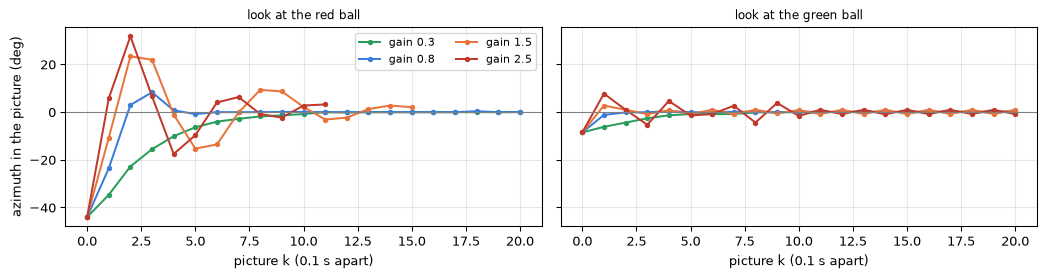

In [12]:
seen_az, real_find = [], lab.find_ball
def logging_find(image, rgb):                          # the lab's find_ball, recording each azimuth it gives
    uv = real_find(image, rgb)
    seen_az.append(math.degrees(math.atan(-uv[0])) if uv is not None else np.nan)
    return uv
lab.find_ball, shipped_gain = logging_find, lab.GAIN
fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)
with _new_renderer(body.model, lab.RESOLUTION, lab.RESOLUTION) as rend:
    for ax, ball in zip(axes, ("red", "green")):
        for g, c in zip((0.3, 0.8, 1.5, 2.5), ("#2a9d5c", "#3b7dd8", "#e8743b", "#c0392b")):
            lab.GAIN, seen_az = g, []
            lab.scene(body, 1); ok, msg, truth = lab.obey(body, rend, f"look at the {ball} ball")
            ax.plot(range(len(seen_az)), seen_az, "o-", color=c, ms=3, lw=1.5, label=f"gain {g}")
            print(f"{ball:5s} gain {g}: {msg:40s} standing {str(body.standing):5s} "
                  f"furthest past the middle {np.nanmax(seen_az[1:]):+5.1f} deg")
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xlabel("picture k (0.1 s apart)"); ax.grid(alpha=0.3)
        ax.set_title(f"look at the {ball} ball", fontsize=9)
lab.find_ball, lab.GAIN = real_find, shipped_gain
axes[0].set_ylabel("azimuth in the picture (deg)"); axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

Red starts 44° off, at the edge of the picture. 0.3 creeps in; 0.8
**overshoots** by 8°, which the model says cannot happen below 1; at 1.5
and 2.5 the torso swings back and forth, the robot starts to fall
(`standing False`), the ball leaves the picture and the robot refuses.
Green starts 8° off and every gain, even 2.5, settles: the model says
2.5 must diverge, but the waist twists the pelvis the other way and the
camera turns less than commanded (measured in an earlier version: a 28°
command turned the camera 66 % of it in 0.1 s). **The body is not the
model**, and a large error is where that matters.

------------------------------------------------------------------------

## Words → a colour

In [13]:
print(inspect.getsource(lab.colour_of))
for words in ("look at the green ball", "LOOK AT THE GREEN BALL!", "the crimson one",
              "not the red one, the blue one", "greenish"):
    print(f"{words!r:34s} -> {lab.colour_of(words)}")

def colour_of(words):
    from soc4180.vision import COLOURS
    known = [w for w in re.findall(r"[a-z]+", words.lower()) if w in COLOURS]
    return known[0] if known else None

'look at the green ball'           -> green
'LOOK AT THE GREEN BALL!'          -> green
'the crimson one'                  -> None
'not the red one, the blue one'    -> red
'greenish'                         -> None

Lower-case, split into words, keep the ones that name a ball colour,
take the first. That is a **lookup table** with four entries: it never
guesses, which is its strength (“crimson” gets `None`, so the robot
refuses). It is also its limit: “crimson” *is* red to a person,
“greenish” is not a word it knows, and “not the red one” picks red,
because a list of words has no grammar.

------------------------------------------------------------------------

## `colour_of`, line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `from soc4180.vision import COLOURS` | the dictionary of ball colours | its four keys, `red green blue yellow`, are the only words the robot knows |
| `words.lower()` | `"LOOK AT THE GREEN BALL!"` → `"look at the green ball!"` | the pattern below matches lower case only |
| `re.findall(r"[a-z]+", ...)` | every run of letters: `["look", "at", "the", "green", "ball"]` | spaces and punctuation split words; `"greenish"` stays one word |
| `if w in COLOURS` | keeps a word only if it is exactly a key | `"crimson"` and `"greenish"` are dropped |
| `known[0]` | the **first** colour word | `"not the red one, the blue one"` → `red` |
| `else None` | no colour word at all | `obey` refuses at once, before anything moves |

A list comprehension (`[w for w in ... if ...]`) is a loop and a filter
in one line.

------------------------------------------------------------------------

## `obey`: one instruction, from `lab.py` (1 of 2)

In [14]:
src = inspect.getsource(lab.obey).splitlines()
print("\n".join(src[:20]))

def obey(body, renderer, words, dim=1.0):
    from soc4180.vision import CAMERA, COLOURS, ball_direction

    colour = colour_of(words)
    if colour is None:
        return False, "refused: no colour I know in those words", None
    rgb = np.asarray(COLOURS[colour]) * dim
    w = body.act("waist_yaw")
    lo, hi = body.model.actuator_ctrlrange[w]

    def picture():
        renderer.update_scene(body.data, camera=CAMERA)
        return renderer.render()

    for _ in range(20):                                            # 2 s of looking and turning
        uv = find_ball(picture(), rgb)
        if uv is None:
            return False, f"refused: I do not see a {colour} ball", None
        azimuth = math.atan(-uv[0])
        body.data.ctrl[w] = float(np.clip(body.data.ctrl[w] + GAIN * azimuth, lo, hi))

Step 1 refuses before anything moves. `rgb * dim` is the colour to look
for (the `--dim` experiment scales the lights and tells the robot so).
The loop is the last two slides: 20 pictures, 2 s; inside it, a `None`
from `find_ball` is an immediate refusal.

------------------------------------------------------------------------

## `obey`, line by line: before the loop

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `from soc4180.vision import CAMERA, COLOURS, ball_direction` | the camera’s name `"head"`, the colours, and the simulator’s answer key | `ball_direction` is used only for the reported `truth` |
| `colour = colour_of(words)`; `if colour is None: return False, ..., None` | step 1, and a refusal before anything moves | `None` as the third value prints as `-` |
| `rgb = np.asarray(COLOURS[colour]) * dim` | the colour to look for, every channel scaled by `dim` (30 % at `--dim 0.3`) | dimmer lights make darker pixels; the robot is told the light level |
| `w = body.act("waist_yaw")` | the waist-yaw servo’s actuator index | `body.data.ctrl[w]` is the waist’s target angle |

*(continued on the next slide)*

------------------------------------------------------------------------

## `obey`, line by line: before the loop (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `lo, hi = body.model.actuator_ctrlrange[w]` | the target’s limits, −2.618 .. +2.618 rad (the joint’s range) | the loop must never ask for an angle the joint cannot reach |
| `renderer.update_scene(body.data, camera=CAMERA)` | copies the robot’s and the balls’ current poses into the renderer, seen from `head` | a picture of *now*, after the last turn |
| `renderer.render()` | draws and returns a `(64, 64, 3)` `uint8` array | the `image` that `find_ball` reads |

`picture()` is defined inside `obey`, so it can use `body` and
`renderer` without being passed them. The renderer was made once, in
`main`, at `RESOLUTION`.

------------------------------------------------------------------------

## `obey`, line by line: the loop

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `for _ in range(20):` | 20 rounds of 0.1 s | 2 s of looking and turning |
| `uv = find_ball(picture(), rgb)` | a new picture, then the ball in it | the sensor read, every round |
| `if uv is None: return False, f"refused: ...", None` | the ball left the picture (gain 2.5) or was never in it (hidden) | refuse at once, and say why |
| `azimuth = math.atan(-uv[0])` | ${\color{#3b7dd8}{a}} = \arctan(-{\color{#e8743b}{u}})$, radians, left + | only ${\color{#e8743b}{u}}$: the column depends on the azimuth alone |
| `body.data.ctrl[w] + GAIN * azimuth` | the new waist target: old target $+\ {\color{#8e44ad}{g}}\,{\color{#3b7dd8}{a}}$ | the P step of *Closing the loop* |
| `np.clip(..., lo, hi)`, `float(...)` | keeps the target in range; one plain number into `ctrl` | a safe command |
| `body.step(0.1)` (first line of the next slide) | 0.1 s of physics: the waist servo moves toward the target | the next picture sees the turned body |

The loop never stops early on success: it always runs 20 rounds, then
checks.

------------------------------------------------------------------------

## `obey`: the check (2 of 2)

In [15]:
print("\n".join(src[20:]))

        body.step(0.1)

    uv = find_ball(picture(), rgb)                                 # the check, from the picture
    truth = math.degrees(ball_direction(body.model, body.data, ["red", "green", "blue", "yellow"].index(colour))[0])
    if not body.standing:
        return False, "failed: fell over while turning", truth
    if uv is None or abs(math.degrees(math.atan(-uv[0]))) > CENTRED_DEG:
        return False, f"failed: the {colour} ball is not in the middle", truth
    return True, f"done: {colour} in the middle (waist {math.degrees(body.data.qpos[body.act_q[w]]):+.0f} deg)", truth

After turning, **one more picture**, and the same detector must find the
ball within `CENTRED_DEG` (5°) of the middle, with the robot still
standing. `truth` comes from the simulator and is only *reported*, as
the “true error” column: the robot’s own answer never uses it. On a real
robot that column does not exist.

------------------------------------------------------------------------

## `obey`, line by line: the check and the true error

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `uv = find_ball(picture(), rgb)` | one more picture after the 20th turn | **the check**, made with the same detector |
| `["red", "green", "blue", "yellow"].index(colour)` | the ball’s mocap index, in the order `Body` made them | which ball to ask the simulator about |
| `ball_direction(body.model, body.data, i)[0]` | the ball’s **true** azimuth from the camera, from `mocap_pos` and the camera’s pose; `[0]` azimuth, `[1]` elevation | the answer key; `math.degrees` for the table |
| `if not body.standing:` | the pelvis dropped below 0.6 m or tilted over 20° | “failed: fell over while turning” |

*(continued on the next slide)*

------------------------------------------------------------------------

## `obey`, line by line: the check and the true error (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `uv is None or abs(math.degrees(math.atan(-uv[0]))) > CENTRED_DEG` | not found, or more than 5° from the middle **in the picture** | “failed: … not in the middle” |
| `body.data.qpos[body.act_q[w]]` | the angle the waist actually reached | reported in “done”, in degrees |
| `return ..., truth` | `truth` is the third value of all three answers | printed as “true error” |

**No `if` in `obey` reads `truth`.** Every decision (refuse, fail, done)
is made from the picture and `body.standing`. Set `truth = None` instead
and the robot behaves identically; only the table loses its column.

------------------------------------------------------------------------

## `main` (1 of 3): flags, the body, the lights

In [16]:
main_src = inspect.getsource(lab.main).splitlines()
print("\n".join(main_src[:18]))

def main(argv=None) -> int:
    ap = argparse.ArgumentParser(description="Week 11: look at the ball the words name.")
    ap.add_argument("--say", default=None, help="one instruction instead of the battery")
    ap.add_argument("--dim", type=float, default=1.0, help="scale the lights (1 = normal)")
    ap.add_argument("--no-viewer", action="store_true")
    args = ap.parse_args(argv)
    try:
        from soc4180.agent import Body
        from soc4180.render import _new_renderer
    except ImportError:
        print("This lab needs torch: run `uv sync --extra rl` once, then try again.")
        return 1

    body = Body()
    if args.dim != 1.0:
        body.model.light_diffuse[:] *= args.dim
        body.model.light_ambient[:] *= args.dim
    renderer = _new_renderer(body.model, RESOLUTION, RESOLUTION)

`main` is what runs when you type
`uv run weeks/11-pixels-and-language/lab.py`.

------------------------------------------------------------------------

## `main` (1 of 3), line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `--say "..."` | one instruction of your own instead of the battery | try a sentence the battery does not |
| `--dim 0.3` | a number, default `1.0` | the dim-room experiment |
| `--no-viewer` | `store_true`: present means `True` | print the table and stop |
| `try: from soc4180.agent import Body ...` / `except ImportError` | `soc4180.agent` imports torch | a clear message instead of a traceback |
| `body = Body()` | **one** robot for all the tests | `scene` resets it before each |
| `body.model.light_diffuse[:] *= args.dim` (and `light_ambient`) | scales the model’s lights in place | measured: the model has one light, diffuse 0.7, ambient 0, so only diffuse changes; MuJoCo’s headlight (`model.vis.headlight`) is not scaled |
| `_new_renderer(body.model, RESOLUTION, RESOLUTION)` | one 64 × 64 renderer, made once | every `picture()` in `obey` reuses it |

------------------------------------------------------------------------

## `main` (2 of 3): the ten tests

In [17]:
print("\n".join(main_src[19:35]))

    if args.say:
        tests = [(0, None, args.say)]
    else:
        tests = [(s, None, f"look at the {c} ball") for s in (1, 2) for c in ("red", "green", "blue", "yellow")]
        tests += [(1, "green", "look at the green ball"),          # the ball is not in view
                  (1, None, "look at the crimson ball")]           # a word it does not know
    print(f"{'scene':>5} {'instruction':28s} {'robot says':52s} {'true error':>10}")
    ok_count = 0
    for seed, hide, words in tests:
        scene(body, seed, hide)
        ok, msg, truth = obey(body, renderer, words, args.dim)
        ok_count += ok
        tag = f"{seed}" + (" (no " + hide + ")" if hide else "")
        print(f"{tag:>5} {words:28s} {msg:52s} {('%+.1f deg' % truth) if truth is not None else '-':>10}")
    print(f"\n{ok_count} of {len(tests)} instructions carried out"
          + ("" if args.say else " (the last two should be refused when the robot is right)"))

------------------------------------------------------------------------

## `main` (2 of 3), line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `tests = [(0, None, args.say)]` | with `--say`: one test, scene seed 0 | your sentence, one scene |
| `[(s, None, f"look at the {c} ball") for s in (1, 2) for c in (...)]` | 2 scenes × 4 colours = **8 looks** | each test is `(seed, hide, words)` |
| `(1, "green", "look at the green ball")` | scene 1 with the green ball behind the robot | right answer: refuse |
| `(1, None, "look at the crimson ball")` | a word it does not know | right answer: refuse |
| `scene(body, seed, hide)`, then `obey(...)` | a fresh scene, then the instruction | tests do not depend on each other |
| `ok_count += ok` | `True` counts as 1 | the “carried out” total |
| `'%+.1f deg' % truth if truth is not None else '-'` | the true error, or `-` when the robot refused before looking | the column the robot never sees |
| the last `print` | “`N` of 10 instructions carried out” | right is 8 of 10: the last two refused |

------------------------------------------------------------------------

## `main` (3 of 3): the replay

In [18]:
print("\n".join(main_src[36:]))

    if args.no_viewer or soc4180.is_colab():
        return 0
    scene(body, 1)
    obey(body, renderer, args.say or "look at the green ball", args.dim)
    frames = body.frames
    print("\nreplaying the last turn; close the window to stop")
    deadline = time.time() + float(os.environ.get("SOC4180_AUTOCLOSE") or 1e12)
    d = body.data
    with soc4180.launch_viewer(body.model, d, passive=True) as viewer:
        while viewer.is_running() and time.time() < deadline:
            for q in frames:
                if not viewer.is_running() or time.time() > deadline:
                    break
                d.qpos[:] = q; mujoco.mj_forward(body.model, d); viewer.sync()
                time.sleep(17 * body.model.opt.timestep)
            time.sleep(0.5)
    return 0

------------------------------------------------------------------------

## `main` (3 of 3), line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `if args.no_viewer or soc4180.is_colab(): return 0` | stop after the table | Colab has no window |
| `scene(body, 1)`; `obey(body, renderer, args.say or "look at the green ball", args.dim)` | one more turn: scene 1, green, or your `--say` words | the turn you will watch (scene 1 even with `--say`) |
| `frames = body.frames` | the `qpos` copies `body.step` recorded, one every 17 physics steps | `reset` emptied it, so only this turn |
| `deadline = ... SOC4180_AUTOCLOSE` | closes the window after that many seconds, if set | `scripts/check_labs.py` uses it; unset, it never closes by itself |

*(continued on the next slide)*

------------------------------------------------------------------------

## `main` (3 of 3), line by line (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `launch_viewer(body.model, d, passive=True)` | opens the window; the script drives it |  |
| `d.qpos[:] = q; mujoco.mj_forward(body.model, d); viewer.sync()` | puts a recorded pose on the screen: no physics re-run | what you see is exactly what was measured |
| `time.sleep(17 * body.model.opt.timestep)` | 17 × 0.002 s between frames | plays back at real speed |
| `time.sleep(0.5)` | a pause, then the turn again | until you close the window |

------------------------------------------------------------------------

## `main`: what you type, and what runs

| you type | tests | then |
|------------------------|------------------------|------------------------|
| `uv run weeks/11-pixels-and-language/lab.py` | the 10: 8 looks, the hidden ball, “crimson” | the replay: scene 1, green |
| `... lab.py --say "look at the blue ball"` | 1: your words on scene 0 | the replay: scene 1, your words |
| `... lab.py --dim 0.3 --no-viewer` | the 10, in the dimmed room | nothing: no window |
| edit `THRESHOLD`, `MIN_PIXELS`, `GAIN` or `find_ball`, then run again | the same 10, your change | the replay of your version |

The next slides run the same ten tests from the notebook, with one
setting changed at a time.

------------------------------------------------------------------------

## The battery: `lab.py`’s ten tests, one setting changed

In [19]:
def battery(threshold=0.25, dim=1.0, gain=0.8, min_pixels=4, show=False):
    """lab.py's ten tests (8 looks, a hidden ball, an unknown word) with one setting changed."""
    keep = lab.THRESHOLD, lab.GAIN, lab.MIN_PIXELS
    lab.THRESHOLD, lab.GAIN, lab.MIN_PIXELS = threshold, gain, min_pixels
    b = Body()
    if dim != 1.0:                                                   # as lab.py --dim
        b.model.light_diffuse[:] *= dim; b.model.light_ambient[:] *= dim
    tests = [(s, None, f"look at the {c} ball") for s in (1, 2) for c in COLOURS]
    tests += [(1, "green", "look at the green ball"), (1, None, "look at the crimson ball")]
    rows = []
    with _new_renderer(b.model, lab.RESOLUTION, lab.RESOLUTION) as rend:
        for seed, hide, words in tests:
            lab.scene(b, seed, hide); ok, msg, truth = lab.obey(b, rend, words, dim)
            rows.append((seed, hide, words, ok, msg, truth))
            if show:
                t = f"{truth:+6.1f} deg" if truth is not None else "-"
                print(f"{seed}{' no ' + hide if hide else '':9s} {words:25s} {msg:46s} {t:>10}")
    lab.THRESHOLD, lab.GAIN, lab.MIN_PIXELS = keep
    return rows

def summary(label, rows):
    looks = [r for r in rows if r[1] is None and "crimson" not in r[2]]
    done = [r for r in looks if r[3]]
    worst = max((abs(r[5]) for r in done), default=float("nan"))
    hid = next(r for r in rows if r[1])
    print(f"{label:16s} done {sum(r[3] for r in rows):2d} of 10 | looks done {len(done)} of 8, worst true error "
          f"{worst:5.1f} deg | hidden ball: {'DONE' if hid[3] else 'refused'}"
          + (f" ({hid[5]:+.0f} deg)" if hid[5] is not None else ""))

`battery` runs `lab.py`’s tests (8 looks, the green ball hidden,
“crimson”); `summary` gives one line: looks “done”, their **worst true
error**, the hidden ball. Setting `lab.THRESHOLD` works like editing the
file: `find_ball` reads it when it runs.

------------------------------------------------------------------------

## The battery, as shipped

In [20]:
t0 = time.time(); shipped = battery(show=True)
print(f"{sum(r[3] for r in shipped)} of 10 done ({time.time() - t0:.1f} s)")

1          look at the red ball      done: red in the middle (waist -46 deg)          +0.1 deg
1          look at the green ball    done: green in the middle (waist -8 deg)         +0.3 deg
1          look at the blue ball     done: blue in the middle (waist +11 deg)         -0.2 deg
1          look at the yellow ball   done: yellow in the middle (waist +41 deg)       +0.0 deg
2          look at the red ball      done: red in the middle (waist +45 deg)          -0.1 deg
2          look at the green ball    done: green in the middle (waist +9 deg)         -0.2 deg
2          look at the blue ball     done: blue in the middle (waist -41 deg)         +0.3 deg
2          look at the yellow ball   done: yellow in the middle (waist -11 deg)       +0.1 deg
1 no green look at the green ball    refused: I do not see a green ball                      -
1          look at the crimson ball  refused: no colour I know in those words                -
8 of 10 done (1.6 s)

Eight looks done within a fraction of a degree, the hidden ball refused,
the unknown word refused. All ten answers are right; the same table is
what `lab.py` prints on your laptop.

------------------------------------------------------------------------

## The learned versions

The lab hand-writes steps 1 and 2. Earlier versions of this week trained
networks for both; measured then, with `torch.set_num_threads(4)` (not
re-run here):

**A small CNN reads the direction from pixels** (3 convolutions + 2
linear layers, 146,370 parameters, 4,000 rendered red-ball pictures,
labels free from the simulator):

| trained on | red ball, as trained | blue ball | dim room (30 %) |
|------------------|------------------|------------------|------------------|
| red balls only | **1.0°** | 27.8° | 15.2° |
| random colour and light (**visual randomisation**) | 4.4° | 9.4° | 4.2° |

Always guessing the average direction: 26.0°. The network is excellent
on the world it was shown and **worse than guessing** on a ball of
another colour; randomising the pictures fixes what it randomises, and
costs accuracy on the easy case.

**A words + pixels attention model** (a bag of words → a query; the
picture → a key per cell; the named ball’s cell by a softmax; 20,032
parameters): 2.0° on phrasings it was trained on, 2.1° on new phrasings,
about **31° (chance)** for “crimson”, the same as no colour word at all.

------------------------------------------------------------------------

## Confidently wrong

The same attention model, asked for a ball that is **behind the robot**:
its heat map still peaked, mean 0.60 and **up to 0.98**, against a mean
of 0.88 when the ball was there (200 pictures, measured as above). It
had only ever been shown pictures with the ball present, so it had no
way to say *“not here”*. The CNN, likewise, gives a direction for any
picture at all.

|  | can it say “I do not see it”? | what it does on a world it was not shown |
|------------------------|------------------------|------------------------|
| `find_ball` | yes: fewer than `MIN_PIXELS` pixels | depends on `THRESHOLD` (next slides) |
| the CNN | no | 27.8° off on a blue ball, no warning |
| the attention model | no | points at *something*, confidence up to 0.98 |

A network’s own output is not a check on that network. So a robot needs
a check, and the check must not share the failure. The lab’s check uses
the same `find_ball`. Watch what that buys.

------------------------------------------------------------------------

## The check that passes its own mistake

In [21]:
t0 = time.time()
summary("as shipped", shipped)
summary("THRESHOLD 0.05", battery(threshold=0.05))
summary("THRESHOLD 0.6", battery(threshold=0.6))
summary("--dim 0.3", battery(dim=0.3))
g25 = battery(gain=2.5); summary("GAIN 2.5", g25)
print("  GAIN 2.5 refuses:", "; ".join(f"scene {r[0]} {r[2].split()[3]} (shipped waist {s[4].split()[-2]} deg)"
                                     for r, s in zip(g25, shipped) if not r[3] and r[1] is None and "crimson" not in r[2]))
summary("MIN_PIXELS 1", battery(min_pixels=1))
print(f"({time.time() - t0:.0f} s)")

as shipped       done  8 of 10 | looks done 8 of 8, worst true error   0.3 deg | hidden ball: refused
THRESHOLD 0.05   done  0 of 10 | looks done 0 of 8, worst true error   nan deg | hidden ball: refused
THRESHOLD 0.6    done  9 of 10 | looks done 8 of 8, worst true error  38.9 deg | hidden ball: DONE (+149 deg)
--dim 0.3        done  9 of 10 | looks done 8 of 8, worst true error  41.3 deg | hidden ball: DONE (-173 deg)
GAIN 2.5         done  4 of 10 | looks done 4 of 8, worst true error   1.8 deg | hidden ball: refused
  GAIN 2.5 refuses: scene 1 red (shipped waist -46 deg); scene 1 yellow (shipped waist +41 deg); scene 2 red (shipped waist +45 deg); scene 2 blue (shipped waist -41 deg)
MIN_PIXELS 1     done  8 of 10 | looks done 8 of 8, worst true error   0.3 deg | hidden ball: refused
(7 s)

Read the “true error” column the robot never sees. At `THRESHOLD 0.6`
and in the dim room the robot reports **“done” on looks up to 39° and
41° off, and “done” on the hidden ball**, half a turn away. Too strict
(0.05) fails *safely*: it refuses everything. Gain 2.5 fails safely too:
it loses the balls that need a large turn, and says so.

------------------------------------------------------------------------

## Why the check failed, and what would catch it

The check asks the detector that made the mistake whether it made a
mistake. At `THRESHOLD 0.6` “green” includes pixels that are not the
green ball, so `find_ball` centres on them, the robot turns to them, and
the final picture shows them, centred. **Same sense, same error, so the
check agrees.**

A check is worth something only if it can fail when the action failed:
**a second, independent sense**.

The “true error” column is the one you may *not* use: it is the
simulator’s answer key. On the term project, a claim of success needs a
check that could have said no.

## What would catch it

Candidates for the second sense, each with what it costs:

| second sense | catches | still fooled by |
|------------------------|------------------------|------------------------|
| the blob’s **shape**: a ball is a round blob of the right size for its distance | a floor patch or a scatter of pixels counted as “green” | a round green thing that is not the ball |
| a **tighter threshold** in the check than in the search | loose matches that only pass the loose test | dim light, which moves every pixel |
| **another viewpoint**: turn a little and predict where the ball must move in the picture | a target that does not move like an object at that bearing | nothing cheap |
| a **different detector** (a network) next to `find_ball` | failures the two do not share | failures they share (dim light hurts both) |

------------------------------------------------------------------------

## Where a language model would fit

`colour_of` is the part a large language model replaces: given `obey` as
a **tool**, it knows that crimson is red. It does not replace the check.

``` python
# Not run: it needs an API key, a network connection and the `anthropic` package (not in uv.lock).
import anthropic, lab
from soc4180.agent import Body
from soc4180.render import _new_renderer
client = anthropic.Anthropic()
look = {"name": "look", "description": "Turn the waist until the named ball is centred. Checks with the camera "
        "and says whether it worked.", "input_schema": {"type": "object", "required": ["colour"],
        "properties": {"colour": {"enum": ["red", "green", "blue", "yellow"]}}}}
body = Body(); rend = _new_renderer(body.model, lab.RESOLUTION, lab.RESOLUTION)
messages = [{"role": "user", "content": "Face the crimson ball."}]
while True:
    reply = client.messages.create(model="claude-opus-5-5", max_tokens=16000,
                                   tools=[look], messages=messages)
    messages.append({"role": "assistant", "content": reply.content})
    if reply.stop_reason != "tool_use":
        break
    results = []
    for block in reply.content:
        if block.type == "tool_use":                     # run the skill; its check is the answer
            ok, msg, _ = lab.obey(body, rend, f"look at the {block.input['colour']} ball")
            results.append({"type": "tool_result", "tool_use_id": block.id, "content": msg, "is_error": not ok})
    messages.append({"role": "user", "content": results})          # all results in one message
```

A lookup fails loudly (`None`); a language model fails **fluently**,
choosing a plausible colour for anything. The more general the planner,
the more the check has to carry. Note what the tool returns: `msg`, the
robot’s check, never the simulator’s `truth`.

------------------------------------------------------------------------

## Lab class: on your laptop

``` bash
uv run weeks/11-pixels-and-language/lab.py                              # the battery, then a replay
uv run weeks/11-pixels-and-language/lab.py --say "look at the blue ball"
uv run weeks/11-pixels-and-language/lab.py --dim 0.3 --no-viewer
```

**What you change** (all in `lab.py`): `find_ball()` itself,
`THRESHOLD`, `MIN_PIXELS`, `GAIN`, and the `--dim` flag. **What you
see:** the battery table (scene, instruction, what the robot says, and
the **true error** from the simulator), the count of instructions
carried out, then the viewer replaying the last turn. Right looks like:
eight looks done near 0°, the last two refused.

**Try** (predict each first; what `lab.py` measured is in brackets):

1.  `THRESHOLD = 0.05` or `0.6`. \[0.05 refuses all 10. 0.6 says “done”
    9 times, up to 39° off, and “sees” the hidden green ball, 149°
    away.\]
2.  `--dim 0.3`. \[says “done” 9 times, up to 41° off; “sees” the hidden
    ball.\]
3.  `GAIN = 2.5`. \[4 of 8 refused: the ball swings out of the
    picture.\]
4.  `MIN_PIXELS = 1`. \[no change here: noise does not look like a
    ball.\]
5.  Write a check that catches 1 and 2 without the true-error column (a
    second sense: the blob’s size and shape, a stricter test, a small
    extra turn).

------------------------------------------------------------------------

## For your term project

Weeks 12–15 are the term project ([projects
README](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/README.md),
[catalogue](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/catalogue.md)).
Projects that start here:

- **P11 — Eyes on the ball.** Find a ball with the head camera and turn
  (or point) at it; which visual change breaks it: colour, light or
  distance?
- **P12 — Words to actions.** A new word or a new skill for the robot,
  with a check that measures whether it worked, and refusals measured on
  scenes without the ball.
- **P4 — Reach while standing.** Point a hand at the ball the camera
  found (IK, weeks 3-4).
- **P14 — Your own proposal**, under the same method.

**The method.** (1) **Predict first**: write the number you expect and
why. (2) **A twin with one change**: every claim is two runs differing
in one setting (one threshold, one gain, one check). (3)
**`results.csv`**: one row per run, every setting and every measured
number, written by the script. (4) **A `CHECK` line**: the script prints
whether the claim held (`CHECK hidden ball refused: PASS`). (5) **Grade
by margins**: a pass line far from your number on both sides, and a
measured wrong answer that fails.

Start from `lab.py`, `soc4180.agent.Body` and `soc4180.vision`
(`camera_model`, `place_ball`, `ball_direction`, `uv_of`,
`angles_of_uv`). The “true error” column is for **grading** your robot,
never for your robot to use.